In [1]:
#@title A1 · Dependencias y Google Drive
!pip install -q tcia_utils pydicom
import os
from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR = "/content/drive/MyDrive/Proyecto_Mamografias_Modelo2"
os.makedirs(DRIVE_DIR, exist_ok=True)
CACHE_NPZ = f"{DRIVE_DIR}/cache_224.npz"
CACHE_CSV = f"{DRIVE_DIR}/indice_imagenes.csv"
HAY_CACHE = os.path.exists(CACHE_NPZ) and os.path.exists(CACHE_CSV)
print("¿Ya existe la caché en Drive?:", HAY_CACHE)
if HAY_CACHE:
    print("→ No necesitas la Parte A. Cambia el runtime a GPU y salta a la PARTE B.")

Mounted at /content/drive
¿Ya existe la caché en Drive?: False


In [2]:
#@title A2 · Descargar metadatos clínicos y DICOM de CMMD (tarda; solo si no hay caché)
import subprocess
os.chdir("/content")
if not HAY_CACHE:
    subprocess.run(["wget", "-q", "-O", "dataset.tcia",
                    "https://www.cancerimagingarchive.net/wp-content/uploads/The-Chinese-Mammography-Database.tcia"], check=True)
    subprocess.run(["wget", "-q", "-O", "CMMD_c_r.xlsx",
                    "https://www.cancerimagingarchive.net/wp-content/uploads/CMMD_clinicaldata_revision.xlsx"], check=True)
    from tcia_utils import idc
    df_descarga = idc.downloadSeries("dataset.tcia", input_type="manifest", format="df")
else:
    print("Se omite la descarga (ya existe la caché).")

In [3]:
#@title A3 · Indexar imágenes (PatientID + lateralidad → etiqueta) y resumen para el EDA
import glob
import pandas as pd
import pydicom

if not HAY_CACHE:
    df_clinico = pd.read_excel("CMMD_c_r.xlsx")
    df_clinico['label'] = df_clinico['classification'].map({'Benign': 0, 'Malignant': 1})

    # Comprobación de la llave (ID1, LeftRight): si hubiera duplicados, el diccionario sobrescribiría etiquetas
    n_dup = int(df_clinico.duplicated(['ID1', 'LeftRight']).sum())
    print(f"Filas clínicas con (ID1, LeftRight) repetido: {n_dup}   <- debe ser 0")

    mapa_clinico = {(r.ID1, r.LeftRight): r.label for r in df_clinico.itertuples()}

    rutas = sorted(glob.glob("**/*.dcm", recursive=True))
    registros, sin_etiqueta = [], 0
    for ruta in rutas:
        ds = pydicom.dcmread(ruta, stop_before_pixels=True)      # solo metadatos (rápido)
        pid = getattr(ds, 'PatientID', None)
        lat = getattr(ds, 'ImageLaterality', None) or getattr(ds, 'Laterality', None)
        if (pid, lat) in mapa_clinico:
            registros.append({
                'ruta': ruta, 'ID1': pid, 'LeftRight': lat, 'label': mapa_clinico[(pid, lat)],
                'Rows': getattr(ds, 'Rows', None), 'Columns': getattr(ds, 'Columns', None),
                'ViewPosition': getattr(ds, 'ViewPosition', None),
                'Fabricante': getattr(ds, 'Manufacturer', None),
                'Modelo_equipo': getattr(ds, 'ManufacturerModelName', None),
            })
        else:
            sin_etiqueta += 1          # imagen de una mama sin fila clínica: se EXCLUYE (ausencia de anotación ≠ benigno)

    df_imagenes = pd.DataFrame(registros)
    df_imagenes['label'] = df_imagenes['label'].astype(int)
    df_imagenes['cohorte'] = df_imagenes['ID1'].str[:2]          # 'D1' o 'D2'

    print(f"\nDICOM encontrados: {len(rutas)} | emparejados con etiqueta: {len(df_imagenes)} | excluidos (sin etiqueta): {sin_etiqueta}")
    print(f"Pacientes con imágenes emparejadas: {df_imagenes['ID1'].nunique()}")
    print("\nImágenes por clase (0=Benign, 1=Malignant):\n", df_imagenes['label'].value_counts().sort_index())
    print("\nVistas (ViewPosition):\n", df_imagenes['ViewPosition'].value_counts(dropna=False))
    print("\nResoluciones más frecuentes:\n", (df_imagenes['Rows'].astype(str) + ' x ' + df_imagenes['Columns'].astype(str)).value_counts().head(5))
    print("\nCohorte × clase:\n", pd.crosstab(df_imagenes['cohorte'], df_imagenes['label']))
    print("\nCohorte × equipo (¿cada cohorte usa equipos distintos?):\n",
          pd.crosstab(df_imagenes['cohorte'], df_imagenes['Modelo_equipo'].fillna('desconocido')))
else:
    print("Se omite la indexación (ya existe la caché).")

Filas clínicas con (ID1, LeftRight) repetido: 0   <- debe ser 0

DICOM encontrados: 5202 | emparejados con etiqueta: 3744 | excluidos (sin etiqueta): 1458
Pacientes con imágenes emparejadas: 1775

Imágenes por clase (0=Benign, 1=Malignant):
 label
0    1112
1    2632
Name: count, dtype: int64

Vistas (ViewPosition):
 ViewPosition
None    3744
Name: count, dtype: int64

Resoluciones más frecuentes:
 2294 x 1914    3744
Name: count, dtype: int64

Cohorte × clase:
 label       0     1
cohorte            
D1       1088  1126
D2         24  1506

Cohorte × equipo (¿cada cohorte usa equipos distintos?):
 Modelo_equipo  desconocido
cohorte                   
D1                    2214
D2                    1530


In [4]:
#@title A4 · Construir y guardar la caché 224×224 (equivale a: min-max → uint8 → Resize 224 bilineal)
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

TAM = 224
if not HAY_CACHE:
    X = np.zeros((len(df_imagenes), TAM, TAM), dtype=np.uint8)
    for i, ruta in enumerate(tqdm(df_imagenes['ruta'])):
        arr = pydicom.dcmread(ruta).pixel_array.astype(np.float32)
        mn, mx = arr.min(), arr.max()
        u8 = ((arr - mn) / (mx - mn) * 255.0).astype(np.uint8) if mx > mn else np.zeros(arr.shape, dtype=np.uint8)
        X[i] = np.asarray(Image.fromarray(u8).resize((TAM, TAM), Image.BILINEAR))
    np.savez_compressed(CACHE_NPZ, X=X)
    df_imagenes.to_csv(CACHE_CSV, index=False)
    print(f"Caché guardada en Drive: {X.shape} | {os.path.getsize(CACHE_NPZ)/1e6:.0f} MB")
else:
    print("Se omite (ya existe la caché).")

  0%|          | 0/3744 [00:00<?, ?it/s]

Caché guardada en Drive: (3744, 224, 224) | 45 MB


In [5]:
#@title A5 · Comprobar que la caché equivale al pipeline ORIGINAL del cuaderno (diferencia ≈ 0)
import torch
from torchvision import transforms

if not HAY_CACHE:
    t_original = transforms.Compose([
        transforms.ToPILImage(), transforms.Grayscale(num_output_channels=3),
        transforms.Resize((224, 224)), transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])
    MEDIA = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    for i in [0, len(df_imagenes) // 2, len(df_imagenes) - 1]:
        arr = pydicom.dcmread(df_imagenes.loc[i, 'ruta']).pixel_array.astype(np.float32)
        u8 = ((arr - arr.min()) / (arr.max() - arr.min()) * 255.0).astype(np.uint8)
        a = t_original(u8)
        b = (torch.from_numpy(X[i]).float().div(255.0).unsqueeze(0).repeat(3, 1, 1) - MEDIA) / STD
        print(f"Imagen {i}: diferencia máxima = {torch.abs(a - b).max().item():.2e}")
    print("\n✅ Parte A terminada. Cambia el runtime a GPU y continúa en la PARTE B.")

Imagen 0: diferencia máxima = 0.00e+00
Imagen 1872: diferencia máxima = 0.00e+00
Imagen 3743: diferencia máxima = 0.00e+00

✅ Parte A terminada. Cambia el runtime a GPU y continúa en la PARTE B.


In [6]:
#@title B1 · Imports, Drive y configuración del experimento
import os, time, json, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models
import torchvision
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, f1_score
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR = "/content/drive/MyDrive/Proyecto_Mamografias_Modelo2"
CACHE_NPZ = f"{DRIVE_DIR}/cache_224.npz"
CACHE_CSV = f"{DRIVE_DIR}/indice_imagenes.csv"
assert os.path.exists(CACHE_NPZ) and os.path.exists(CACHE_CSV), "No hay caché en Drive: ejecuta primero la PARTE A (runtime CPU)."

# ---------------- CONFIGURACIÓN DEL EXPERIMENTO ----------------
# Mismos valores que la línea base ResNet18. SOLO cambia la arquitectura.
ARQUITECTURA = "efficientnet_b0"      # opciones: "efficientnet_b0" | "densenet121"
SEED = 42
EPOCHS = 10
BATCH_SIZE = 32
LR = 1e-4                              # optimizador Adam
SENS_OBJETIVO = 0.95                   # regla para elegir el umbral en VALIDACIÓN
UMBRAL_REFERENCIA = 0.30               # umbral usado con ResNet18 (solo para comparar)
RESUMIR = True                         # reanudar desde el último checkpoint si existe
# ---------------------------------------------------------------

def fijar_semillas(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

fijar_semillas(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "⚠️ SIN GPU: cambia el runtime a GPU")
print("Versiones: torch", torch.__version__, "| torchvision", torchvision.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dispositivo: cpu | ⚠️ SIN GPU: cambia el runtime a GPU
Versiones: torch 2.14.1+cpu | torchvision 0.29.1+cpu


In [7]:
#@title B2 · Partición por paciente (idéntica al cuaderno original) y verificación anti-fuga
X = np.load(CACHE_NPZ)["X"]
df_imagenes = pd.read_csv(CACHE_CSV)
assert len(X) == len(df_imagenes)
df_imagenes["idx_cache"] = np.arange(len(df_imagenes))

# 70% train / 15% val / 15% test, agrupado por paciente (mismo código y semilla que la línea base)
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
train_val_idx, test_idx = next(gss_test.split(df_imagenes, groups=df_imagenes["ID1"]))
df_train_val = df_imagenes.iloc[train_val_idx].reset_index(drop=True)
df_test = df_imagenes.iloc[test_idx].reset_index(drop=True)

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.1765, random_state=SEED)   # 0.1765 * 0.85 ≈ 0.15
train_idx, val_idx = next(gss_val.split(df_train_val, groups=df_train_val["ID1"]))
df_train = df_train_val.iloc[train_idx].reset_index(drop=True)
df_val = df_train_val.iloc[val_idx].reset_index(drop=True)

assert len(set(df_train["ID1"]) & set(df_val["ID1"])) == 0, "¡Fuga entre Train y Val!"
assert len(set(df_train["ID1"]) & set(df_test["ID1"])) == 0, "¡Fuga entre Train y Test!"
assert len(set(df_val["ID1"]) & set(df_test["ID1"])) == 0, "¡Fuga entre Val y Test!"

print(f"Imágenes  -> Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")
print(f"Pacientes -> Train: {df_train['ID1'].nunique()} | Val: {df_val['ID1'].nunique()} | Test: {df_test['ID1'].nunique()}")
print("\nDistribución de clases por partición (0=Benign, 1=Malignant):")
for nombre, d in [("Train", df_train), ("Val", df_val), ("Test", df_test)]:
    print(f"  {nombre}:", d["label"].value_counts().sort_index().to_dict(), "| cohortes:", d["cohorte"].value_counts().to_dict())

# Evidencia reproducible: pacientes por partición (súbelo al repositorio; no contiene imágenes)
pd.concat([
    pd.DataFrame({"ID1": sorted(df_train["ID1"].unique()), "particion": "train"}),
    pd.DataFrame({"ID1": sorted(df_val["ID1"].unique()), "particion": "val"}),
    pd.DataFrame({"ID1": sorted(df_test["ID1"].unique()), "particion": "test"}),
]).to_csv(f"{DRIVE_DIR}/particiones_por_paciente.csv", index=False)
print("\nGuardado: particiones_por_paciente.csv  (compara estos conteos con los del cuaderno original: deben coincidir)")

Imágenes  -> Train: 2618 | Val: 564 | Test: 562
Pacientes -> Train: 1241 | Val: 267 | Test: 267

Distribución de clases por partición (0=Benign, 1=Malignant):
  Train: {0: 776, 1: 1842} | cohortes: {'D1': 1548, 'D2': 1070}
  Val: {0: 160, 1: 404} | cohortes: {'D1': 332, 'D2': 232}
  Test: {0: 176, 1: 386} | cohortes: {'D1': 334, 'D2': 228}

Guardado: particiones_por_paciente.csv  (compara estos conteos con los del cuaderno original: deben coincidir)


In [8]:
#@title B3 · Dataset y DataLoaders (lee de la caché; sin aumentos, igual que la línea base)
MEDIA = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class CacheDataset(Dataset):
    def __init__(self, X, df):
        self.X = X
        self.idx = df["idx_cache"].values
        self.y = df["label"].values
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        img = torch.from_numpy(self.X[self.idx[i]]).float().div(255.0).unsqueeze(0).repeat(3, 1, 1)
        img = (img - MEDIA) / STD
        return img, torch.tensor(int(self.y[i]), dtype=torch.long)

def _seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

g = torch.Generator(); g.manual_seed(SEED)
train_loader = DataLoader(CacheDataset(X, df_train), batch_size=BATCH_SIZE, shuffle=True, num_workers=2,
                          generator=g, worker_init_fn=_seed_worker)
val_loader = DataLoader(CacheDataset(X, df_val), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(CacheDataset(X, df_test), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

xb, yb = next(iter(train_loader))
print("Lote:", xb.shape, yb.shape, "| rango:", float(xb.min()), "a", float(xb.max()))

Lote: torch.Size([32, 3, 224, 224]) torch.Size([32]) | rango: -2.1179039478302 a 2.6225709915161133


In [9]:
#@title B4 · Funciones de modelo y de evaluación
def crear_modelo(nombre, preentrenado=True):
    if nombre == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT if preentrenado else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 2)
    elif nombre == "densenet121":
        m = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT if preentrenado else None)
        m.classifier = nn.Linear(m.classifier.in_features, 2)
    elif nombre == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT if preentrenado else None)
        m.fc = nn.Linear(m.fc.in_features, 2)
    else:
        raise ValueError(f"Arquitectura no soportada: {nombre}")
    return m

def contar_parametros(m):
    return sum(p.numel() for p in m.parameters())

def evaluar(modelo, loader, criterio=None):
    """Devuelve (loss, y_true, score_malignidad). No toca pesos."""
    modelo.eval()
    y_true, y_score, loss_total = [], [], 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = modelo(x)
            if criterio is not None:
                loss_total += criterio(out, y).item() * x.size(0)
            y_score.extend(torch.softmax(out, dim=1)[:, 1].cpu().numpy())
            y_true.extend(y.cpu().numpy())
    return loss_total / len(loader.dataset), np.array(y_true), np.array(y_score)

def metricas_en_umbral(y, s, tau):
    pred = (s >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if (tp + fn) else float("nan")
    espec = tn / (tn + fp) if (tn + fp) else float("nan")
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = 2 * prec * sens / (prec + sens) if (prec + sens) else 0.0
    return {"τ": round(float(tau), 2), "Sensibilidad": round(sens, 4), "Especificidad": round(espec, 4),
            "Precisión": round(prec, 4), "F1": round(f1, 4), "TP": int(tp), "FN": int(fn), "TN": int(tn), "FP": int(fp)}

def seleccionar_umbral(y, s, sens_objetivo=0.95, malla=None):
    """Regla (solo con VALIDACIÓN): el umbral MÁS ALTO cuya sensibilidad sea >= sens_objetivo
    (es decir, maximiza la especificidad sin dejar caer la sensibilidad por debajo del objetivo)."""
    if malla is None:
        malla = np.round(np.arange(0.01, 1.0, 0.01), 2)
    n_pos = (y == 1).sum()
    candidatos = [t for t in malla if ((s >= t) & (y == 1)).sum() / n_pos >= sens_objetivo]
    if not candidatos:
        print(f"⚠️ Ningún umbral alcanza sensibilidad {sens_objetivo}; se usa el más bajo de la malla.")
        return float(min(malla))
    return float(max(candidatos))

def metricas_por_cohorte(df, s_col, tau, min_por_clase=10):
    """Métricas por cohorte (D1/D2). Útil para detectar si el modelo solo 'acierta' por la cohorte."""
    filas = []
    for coh, d in df.groupby("cohorte"):
        y, s = d["label"].values, d[s_col].values
        n_ben, n_mal = int((y == 0).sum()), int((y == 1).sum())
        fila = {"Cohorte": coh, "Imágenes": len(d), "Benignas": n_ben, "Malignas": n_mal}
        if n_ben >= min_por_clase and n_mal >= min_por_clase:
            m = metricas_en_umbral(y, s, tau)
            fila.update({"AUC": round(roc_auc_score(y, s), 4), "Sensibilidad": m["Sensibilidad"], "Especificidad": m["Especificidad"]})
        else:
            fila.update({"AUC": "n/a (muy pocas de una clase)", "Sensibilidad": "-", "Especificidad": "-"})
        filas.append(fila)
    return pd.DataFrame(filas)

def bootstrap_diferencia_auc(df, col_a, col_b, n_boot=1000, seed=42):
    """IC 95% de AUC(a) - AUC(b) remuestreando PACIENTES (no imágenes), para respetar la agrupación."""
    rng = np.random.default_rng(seed)
    grupos = {pid: d.index.values for pid, d in df.groupby("ID1")}
    pids = np.array(list(grupos.keys()))
    y = df["label"].values
    difs = []
    for _ in range(n_boot):
        idx = np.concatenate([grupos[p] for p in rng.choice(pids, size=len(pids), replace=True)])
        if len(np.unique(y[idx])) < 2:
            continue
        difs.append(roc_auc_score(y[idx], df[col_a].values[idx]) - roc_auc_score(y[idx], df[col_b].values[idx]))
    return float(np.mean(difs)), float(np.percentile(difs, 2.5)), float(np.percentile(difs, 97.5))

In [10]:
#@title B5 · Entrenamiento (con checkpoint en Drive: si se desconecta, vuelve a ejecutar esta celda)
fijar_semillas(SEED)
modelo = crear_modelo(ARQUITECTURA).to(device)
criterio = nn.CrossEntropyLoss()
optimizador = optim.Adam(modelo.parameters(), lr=LR)
n_params = contar_parametros(modelo)
print(f"Arquitectura: {ARQUITECTURA} | Parámetros: {n_params/1e6:.2f} M")

RUTA_CKPT = f"{DRIVE_DIR}/{ARQUITECTURA}_checkpoint.pth"
RUTA_PESOS = f"{DRIVE_DIR}/{ARQUITECTURA}_linea_base.pth"
historial = {k: [] for k in ["train_loss", "val_loss", "val_recall", "val_f1", "val_auc"]}
epoca_inicial, tiempo_acum = 0, 0.0

if RESUMIR and os.path.exists(RUTA_CKPT):
    ck = torch.load(RUTA_CKPT, map_location=device, weights_only=False)
    modelo.load_state_dict(ck["modelo"]); optimizador.load_state_dict(ck["optimizador"])
    historial, epoca_inicial, tiempo_acum = ck["historial"], ck["epoca"], ck["tiempo"]
    print(f"↻ Reanudando desde la época {epoca_inicial}/{EPOCHS}")

for epoch in range(epoca_inicial, EPOCHS):
    t0 = time.time()
    modelo.train()
    running = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizador.zero_grad()
        loss = criterio(modelo(x), y)
        loss.backward()
        optimizador.step()
        running += loss.item() * x.size(0)
    train_loss = running / len(train_loader.dataset)

    val_loss, y_val, s_val = evaluar(modelo, val_loader, criterio)
    m05 = metricas_en_umbral(y_val, s_val, 0.5)
    historial["train_loss"].append(float(train_loss)); historial["val_loss"].append(float(val_loss))
    historial["val_recall"].append(float(m05["Sensibilidad"])); historial["val_f1"].append(float(m05["F1"]))
    historial["val_auc"].append(float(roc_auc_score(y_val, s_val)))

    tiempo_acum += time.time() - t0
    torch.save({"modelo": modelo.state_dict(), "optimizador": optimizador.state_dict(),
                "historial": historial, "epoca": epoch + 1, "tiempo": tiempo_acum}, RUTA_CKPT)
    print(f"Época {epoch+1:02d}/{EPOCHS:02d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
          f"Val Recall: {m05['Sensibilidad']:.4f} | Val F1: {m05['F1']:.4f} | Val AUC: {historial['val_auc'][-1]:.4f}")

torch.save(modelo.state_dict(), RUTA_PESOS)
print(f"\nTiempo total de entrenamiento: {tiempo_acum:.1f} s | Pesos guardados en {RUTA_PESOS}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 78.2MB/s]


Arquitectura: efficientnet_b0 | Parámetros: 4.01 M
Época 01/10 | Train Loss: 0.5857 | Val Loss: 0.5345 | Val Recall: 0.9653 | Val F1: 0.8307 | Val AUC: 0.7159
Época 02/10 | Train Loss: 0.5060 | Val Loss: 0.5545 | Val Recall: 0.9554 | Val F1: 0.8310 | Val AUC: 0.7148
Época 03/10 | Train Loss: 0.4281 | Val Loss: 0.5563 | Val Recall: 0.9035 | Val F1: 0.8249 | Val AUC: 0.7114
Época 04/10 | Train Loss: 0.3214 | Val Loss: 0.6234 | Val Recall: 0.7104 | Val F1: 0.7474 | Val AUC: 0.6953
Época 05/10 | Train Loss: 0.2364 | Val Loss: 0.8163 | Val Recall: 0.8886 | Val F1: 0.8122 | Val AUC: 0.6978
Época 06/10 | Train Loss: 0.1637 | Val Loss: 0.9181 | Val Recall: 0.7228 | Val F1: 0.7497 | Val AUC: 0.6874
Época 07/10 | Train Loss: 0.1192 | Val Loss: 0.9733 | Val Recall: 0.8416 | Val F1: 0.7935 | Val AUC: 0.6614
Época 08/10 | Train Loss: 0.1142 | Val Loss: 0.8423 | Val Recall: 0.7970 | Val F1: 0.8030 | Val AUC: 0.7266
Época 09/10 | Train Loss: 0.0998 | Val Loss: 0.9425 | Val Recall: 0.7376 | Val F1: 0.

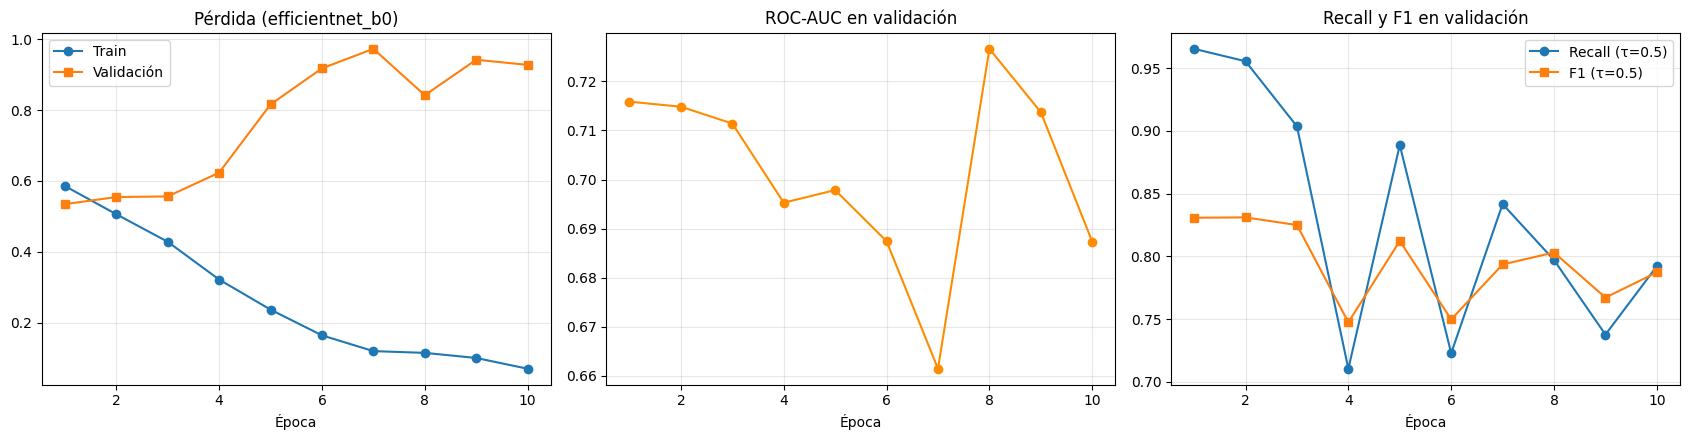

Mejor época por AUC de validación: 8 (AUC=0.7266). Se reportan los pesos de la ÚLTIMA época, igual que la línea base.


In [11]:
#@title B6 · Curvas de entrenamiento (para discutir sobreajuste y convergencia — Hipótesis 1)
ep = range(1, len(historial["train_loss"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(ep, historial["train_loss"], marker="o", label="Train"); ax[0].plot(ep, historial["val_loss"], marker="s", label="Validación")
ax[0].set_title(f"Pérdida ({ARQUITECTURA})"); ax[0].set_xlabel("Época"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ep, historial["val_auc"], marker="o", color="darkorange"); ax[1].set_title("ROC-AUC en validación"); ax[1].set_xlabel("Época"); ax[1].grid(alpha=.3)
ax[2].plot(ep, historial["val_recall"], marker="o", label="Recall (τ=0.5)"); ax[2].plot(ep, historial["val_f1"], marker="s", label="F1 (τ=0.5)")
ax[2].set_title("Recall y F1 en validación"); ax[2].set_xlabel("Época"); ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{DRIVE_DIR}/curvas_{ARQUITECTURA}.png", dpi=150); plt.show()
mejor = int(np.argmax(historial["val_auc"])) + 1
print(f"Mejor época por AUC de validación: {mejor} (AUC={max(historial['val_auc']):.4f}). Se reportan los pesos de la ÚLTIMA época, igual que la línea base.")

ROC-AUC en validación (efficientnet_b0): 0.6873



,τ,Sensibilidad,Especificidad,Precisión,F1,TP,FN,TN,FP
0,0.60,0.7525,0.4875,0.7876,0.7696,304,100,78,82
1,0.50,0.7921,0.4438,0.7824,0.7872,320,84,71,89
2,0.40,0.8218,0.3938,0.7739,0.7971,332,72,63,97
3,0.35,0.8366,0.3562,0.7664,0.8000,338,66,57,103
4,0.30,0.8515,0.3250,0.7611,0.8037,344,60,52,108
5,0.25,0.8614,0.3125,0.7598,0.8074,348,56,50,110



Regla: τ más alto con sensibilidad en validación ≥ 0.95  →  τ* = 0.05


,τ,Sensibilidad,Especificidad,Precisión,F1,TP,FN,TN,FP
0,0.05,0.9505,0.1375,0.7356,0.8294,384,20,22,138


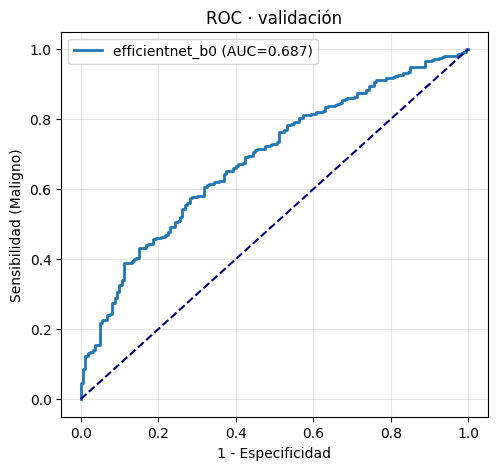

In [12]:
#@title B7 · Validación: umbrales, selección de τ por regla explícita y curva ROC
_, y_val, s_val = evaluar(modelo, val_loader, criterio)
auc_val = roc_auc_score(y_val, s_val)
print(f"ROC-AUC en validación ({ARQUITECTURA}): {auc_val:.4f}\n")

tabla = pd.DataFrame([metricas_en_umbral(y_val, s_val, t) for t in [0.60, 0.50, 0.40, 0.35, 0.30, 0.25]])
display(tabla)

TAU_SELECCIONADO = seleccionar_umbral(y_val, s_val, SENS_OBJETIVO)
print(f"\nRegla: τ más alto con sensibilidad en validación ≥ {SENS_OBJETIVO}  →  τ* = {TAU_SELECCIONADO:.2f}")
display(pd.DataFrame([metricas_en_umbral(y_val, s_val, TAU_SELECCIONADO)]))

fpr, tpr, _ = roc_curve(y_val, s_val)
plt.figure(figsize=(5.5, 5)); plt.plot(fpr, tpr, lw=2, label=f"{ARQUITECTURA} (AUC={auc_val:.3f})"); plt.plot([0, 1], [0, 1], "--", color="navy")
plt.xlabel("1 - Especificidad"); plt.ylabel("Sensibilidad (Maligno)"); plt.title("ROC · validación"); plt.legend(); plt.grid(alpha=.3); plt.show()

In [13]:
#@title B8 · Validación por cohorte (D1 vs D2): ¿el modelo aprende la lesión o la cohorte?
df_val_eval = df_val.copy()
df_val_eval["score_modelo2"] = s_val
display(metricas_por_cohorte(df_val_eval, "score_modelo2", TAU_SELECCIONADO))
print("Nota: D2 contiene casi solo casos malignos (según el EDA). Si el AUC dentro de D1 es mucho menor que el global,\n"
      "parte del desempeño global podría deberse a diferencias de cohorte y no a la patología. Documentarlo como limitación.")

,Cohorte,Imágenes,Benignas,Malignas,AUC,Sensibilidad,Especificidad
0,D1,332,156,176,0.646,0.9375,0.1346
1,D2,232,4,228,n/a (muy pocas de una clase),-,-


Nota: D2 contiene casi solo casos malignos (según el EDA). Si el AUC dentro de D1 es mucho menor que el global,
parte del desempeño global podría deberse a diferencias de cohorte y no a la patología. Documentarlo como limitación.


In [14]:
#@title B9 · (Opcional) Comparación con la línea base ResNet18 en el MISMO conjunto de validación
# Copia tu archivo de pesos a Drive con este nombre: /MyDrive/Proyecto_Mamografias_Modelo2/resnet18_linea_base.pth
RUTA_RESNET18 = f"{DRIVE_DIR}/resnet18_linea_base.pth"

if not os.path.exists(RUTA_RESNET18):
    print("No se encontró resnet18_linea_base.pth en Drive: se omite la comparación. (Copia ahí tu .pth y vuelve a ejecutar.)")
else:
    resnet = crear_modelo("resnet18", preentrenado=False)
    resnet.load_state_dict(torch.load(RUTA_RESNET18, map_location=device))
    resnet = resnet.to(device)
    _, y_val_r, s_val_r = evaluar(resnet, val_loader)
    assert (y_val_r == y_val).all(), "Los conjuntos de validación no coinciden"
    tau_r = seleccionar_umbral(y_val, s_val_r, SENS_OBJETIVO)

    def fila(nombre, params, s, tau_sel):
        m05, mref, msel = (metricas_en_umbral(y_val, s, t) for t in (0.5, UMBRAL_REFERENCIA, tau_sel))
        return {"Modelo": nombre, "Parámetros (M)": round(params / 1e6, 2), "AUC val": round(roc_auc_score(y_val, s), 4),
                "Sens@0.5": m05["Sensibilidad"], "Espec@0.5": m05["Especificidad"],
                f"Sens@{UMBRAL_REFERENCIA}": mref["Sensibilidad"], f"Espec@{UMBRAL_REFERENCIA}": mref["Especificidad"],
                "τ* (sens≥obj.)": round(tau_sel, 2), "Sens@τ*": msel["Sensibilidad"], "Espec@τ*": msel["Especificidad"]}

    comparacion = pd.DataFrame([fila("resnet18", contar_parametros(resnet), s_val_r, tau_r),
                                fila(ARQUITECTURA, n_params, s_val, TAU_SELECCIONADO)])
    display(comparacion.T)
    comparacion.to_csv(f"{DRIVE_DIR}/comparacion_validacion.csv", index=False)

    df_cmp = df_val.copy().reset_index(drop=True)
    df_cmp["score_modelo2"], df_cmp["score_resnet18"] = s_val, s_val_r
    media, lo, hi = bootstrap_diferencia_auc(df_cmp, "score_modelo2", "score_resnet18")
    print(f"\nAUC({ARQUITECTURA}) − AUC(resnet18) en validación: {media:+.4f}  IC95% [{lo:+.4f}, {hi:+.4f}]  (bootstrap por paciente)")
    print("Si el IC incluye 0, la diferencia NO es concluyente con este tamaño de validación.")
    print("\nPor cohorte (resnet18):"); df_cmp["s"] = s_val_r; display(metricas_por_cohorte(df_cmp, "s", tau_r))

No se encontró resnet18_linea_base.pth en Drive: se omite la comparación. (Copia ahí tu .pth y vuelve a ejecutar.)


In [15]:
#@title B10 · 🔒 CONJUNTO DE PRUEBA — ejecutar UNA SOLA VEZ, después de decidir modelo y τ en validación
EVALUAR_TEST = False   # ⚠️ Cámbialo a True solo cuando la decisión ya esté tomada. No ajustes nada después de ver estos resultados.

if not EVALUAR_TEST:
    print("Prueba NO evaluada todavía (correcto). Decide primero con la validación.")
else:
    from datetime import datetime
    _, y_test, s_test = evaluar(modelo, test_loader)
    tau = TAU_SELECCIONADO                      # τ fijado en validación
    m = metricas_en_umbral(y_test, s_test, tau)
    print(f"=== PRUEBA · {ARQUITECTURA} · τ={tau:.2f} (elegido en validación) ===")
    print(f"Matriz de confusión [[TN FP],[FN TP]]: [[{m['TN']} {m['FP']}], [{m['FN']} {m['TP']}]]")
    print(f"Sensibilidad: {m['Sensibilidad']} | Especificidad: {m['Especificidad']} | Precisión: {m['Precisión']} | F1: {m['F1']} | ROC-AUC: {roc_auc_score(y_test, s_test):.4f}")
    df_test_eval = df_test.copy(); df_test_eval["score_modelo2"] = s_test
    display(metricas_por_cohorte(df_test_eval, "score_modelo2", tau))
    with open(f"{DRIVE_DIR}/registro_uso_test.txt", "a") as f:   # evidencia de que el test se usó una sola vez
        f.write(f"{datetime.now().isoformat()} | {ARQUITECTURA} | tau={tau:.2f} | AUC={roc_auc_score(y_test, s_test):.4f}\n")

Prueba NO evaluada todavía (correcto). Decide primero con la validación.


In [16]:
#@title B11 · Ficha del experimento (cópiala a la bitácora / informe)
ficha = {
    "arquitectura": ARQUITECTURA, "parametros_millones": round(n_params / 1e6, 2), "preentrenado": "ImageNet (transfer learning)",
    "semilla": SEED, "epocas": EPOCHS, "batch_size": BATCH_SIZE, "optimizador": "Adam", "learning_rate": LR,
    "entrada": "224x224, gris a 3 canales, normalización ImageNet, sin aumentos",
    "particion": "70/15/15 por paciente (GroupShuffleSplit, semilla 42)",
    "imagenes_train_val_test": [len(df_train), len(df_val), len(df_test)],
    "pacientes_train_val_test": [int(df_train["ID1"].nunique()), int(df_val["ID1"].nunique()), int(df_test["ID1"].nunique())],
    "tiempo_entrenamiento_s": round(tiempo_acum, 1), "dispositivo": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "torch": torch.__version__, "torchvision": torchvision.__version__,
    "auc_validacion": round(float(roc_auc_score(y_val, s_val)), 4), "regla_umbral": f"sensibilidad_val >= {SENS_OBJETIVO}", "tau_seleccionado": TAU_SELECCIONADO,
}
print(json.dumps(ficha, indent=2, ensure_ascii=False))
with open(f"{DRIVE_DIR}/ficha_{ARQUITECTURA}.json", "w") as f:
    json.dump(ficha, f, indent=2, ensure_ascii=False)

{
  "arquitectura": "efficientnet_b0",
  "parametros_millones": 4.01,
  "preentrenado": "ImageNet (transfer learning)",
  "semilla": 42,
  "epocas": 10,
  "batch_size": 32,
  "optimizador": "Adam",
  "learning_rate": 0.0001,
  "entrada": "224x224, gris a 3 canales, normalización ImageNet, sin aumentos",
  "particion": "70/15/15 por paciente (GroupShuffleSplit, semilla 42)",
  "imagenes_train_val_test": [
    2618,
    564,
    562
  ],
  "pacientes_train_val_test": [
    1241,
    267,
    267
  ],
  "tiempo_entrenamiento_s": 6177.2,
  "dispositivo": "cpu",
  "torch": "2.14.1+cpu",
  "torchvision": "0.29.1+cpu",
  "auc_validacion": 0.6873,
  "regla_umbral": "sensibilidad_val >= 0.95",
  "tau_seleccionado": 0.05
}
